In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from sklearn.linear_model import Lasso
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA

np.random.seed(42)

def set_nyt_style():
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['figure.facecolor'] = '#FFFFFF'
    plt.rcParams['axes.facecolor'] = '#FFFFFF'
    plt.rcParams['axes.edgecolor'] = '#CCCCCC'
    plt.rcParams['axes.linewidth'] = 0.8
    plt.rcParams['grid.color'] = '#E5E5E5'
    plt.rcParams['grid.linestyle'] = '--'
    plt.rcParams['grid.alpha'] = 0.7
    plt.rcParams['axes.spines.top'] = False
    plt.rcParams['axes.spines.right'] = False
    plt.rcParams['axes.spines.left'] = True
    plt.rcParams['axes.spines.bottom'] = True
    plt.rcParams['xtick.color'] = '#333333'
    plt.rcParams['ytick.color'] = '#333333'
    plt.rcParams['axes.labelcolor'] = '#222222'
    plt.rcParams['axes.titlesize'] = 13
    plt.rcParams['axes.titleweight'] = 'bold'

set_nyt_style()

CORES = {
    'sp100': '#0F4C81',      # Azul Marinho Principal (S&P 100)
    'sp100_sec': '#2B6999',  # Azul Secundário (Apresentação 1)
    'ibov': '#1B4D3E',       # Verde Esmeralda Fechado (IBOVESPA)
    'ibov_sec': '#2E7D67',   # Verde Secundário
    'alerta': '#C53030',     # Vermelho Editorial (Cortes / Destaque)
    'laranja': '#D97706',    # Âmbar para Modelos Alternativos
    'roxo': '#5B21B6',       # Roxo Sóbrio para Clustering
    'neutro': '#A0AEC0',     # Cinza claro (Contexto / Baselines)
    'grafite': '#1A202C'     # Preto/Grafite para o Benchmark
}

In [4]:
def carregar_e_preparar_mercado(
    path_precos, path_indice, path_setores, col_ticker, col_setor,
    fim_treino='2024-12-31', fim_valid='2025-12-31', limite_nulos_pct=5.0
):
    """
    Carrega preços brutos e índice, aplica filtro de completude APENAS na janela
    de treino (evitando look-ahead bias), preenche resíduos via ffill e divide
    em Treino, Validação e Teste.
    """
    precos = pd.read_csv(path_precos, index_col='Date', parse_dates=True)
    indice = pd.read_csv(path_indice, index_col='Date', parse_dates=True).squeeze()
    if isinstance(indice, pd.DataFrame):
        indice = indice.iloc[:, 0]

    # 1. Filtrar ações com base APENAS nos dados até o fim do treino
    precos_treino_raw = precos.loc[:fim_treino]
    pct_nulos_treino = precos_treino_raw.isna().mean() * 100
    acoes_validas = pct_nulos_treino[pct_nulos_treino <= limite_nulos_pct].index.tolist()

    # 2. Forward fill apenas para frente (nunca bfill para não vazar preço futuro)
    precos_clean = precos[acoes_validas].ffill().dropna(how='any')
    indice_clean = indice.ffill().dropna()

    # 3. Retornos logarítmicos diários alinhados pelo calendário da bolsa
    ret_acoes = np.log(precos_clean / precos_clean.shift(1)).dropna(how='any')
    ret_idx = np.log(indice_clean / indice_clean.shift(1)).dropna()

    datas_comuns = ret_acoes.index.intersection(ret_idx.index)
    ret_acoes = ret_acoes.loc[datas_comuns]
    ret_idx = ret_idx.loc[datas_comuns]

    # 4. Mapeamento Setorial
    df_set = pd.read_csv(path_setores)
    df_set['clean_t'] = (
        df_set[col_ticker].astype(str)
        .str.replace('.SA', '', regex=False)
        .str.replace('-', '.', regex=False).str.strip()
    )
    mapa_raw = dict(zip(df_set['clean_t'], df_set[col_setor]))
    mapa_setores = {}
    for col in ret_acoes.columns:
        c_clean = col.replace('.SA', '').replace('-', '.').strip()
        mapa_setores[col] = mapa_raw.get(c_clean, 'Outros')

    # 5. Divisão Temporal Estrita
    treino_X = ret_acoes.loc[:fim_treino]
    treino_y = ret_idx.loc[:fim_treino]

    inicio_val = (pd.to_datetime(fim_treino) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    val_X = ret_acoes.loc[inicio_val:fim_valid]
    val_y = ret_idx.loc[inicio_val:fim_valid]

    inicio_teste = (pd.to_datetime(fim_valid) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    teste_X = ret_acoes.loc[inicio_teste:]
    teste_y = ret_idx.loc[inicio_teste:]

    return {
        'ret_acoes': ret_acoes, 'ret_idx': ret_idx, 'setores': mapa_setores,
        'treino_X': treino_X, 'treino_y': treino_y,
        'val_X': val_X, 'val_y': val_y,
        'teste_X': teste_X, 'teste_y': teste_y
    }

dados_sp = carregar_e_preparar_mercado(
    'sp100_precos.csv', 'sp100_indice.csv', 'SP100_wikipedia_21set2026.csv', 'Symbol', 'Sector'
)
dados_ib = carregar_e_preparar_mercado(
    'ibov_precos.csv', 'ibov_indice.csv', 'IBOVESPA_B3_24set2026.csv', 'Codigo', 'Setor'
)

# Sobrescrever os arquivos limpos garantindo 0 NaNs para o app e etapas futuras
dados_sp['ret_acoes'].to_csv('sp100_retornos_limpos.csv')
dados_ib['ret_acoes'].to_csv('ibov_retornos_limpos.csv')

for nome, d in [('S&P 100 (^OEX)', dados_sp), ('IBOVESPA (^BVSP)', dados_ib)]:
    print(f"=== {nome} | Ativos Válidos: {d['ret_acoes'].shape[1]} ===")
    print(f"  Treino    : {d['treino_X'].index[0].date()} -> {d['treino_X'].index[-1].date()} ({len(d['treino_X'])} pregões)")
    print(f"  Validação : {d['val_X'].index[0].date()} -> {d['val_X'].index[-1].date()} ({len(d['val_X'])} pregões)")
    print(f"  Teste OOS : {d['teste_X'].index[0].date()} -> {d['teste_X'].index[-1].date()} ({len(d['teste_X'])} pregões)\n")

=== S&P 100 (^OEX) | Ativos Válidos: 99 ===
  Treino    : 2022-01-04 -> 2024-12-31 (752 pregões)
  Validação : 2025-01-02 -> 2025-12-31 (250 pregões)
  Teste OOS : 2026-01-02 -> 2026-10-01 (188 pregões)

=== IBOVESPA (^BVSP) | Ativos Válidos: 74 ===
  Treino    : 2022-01-04 -> 2024-12-30 (748 pregões)
  Validação : 2025-01-02 -> 2025-12-30 (250 pregões)
  Teste OOS : 2026-01-02 -> 2026-10-01 (188 pregões)



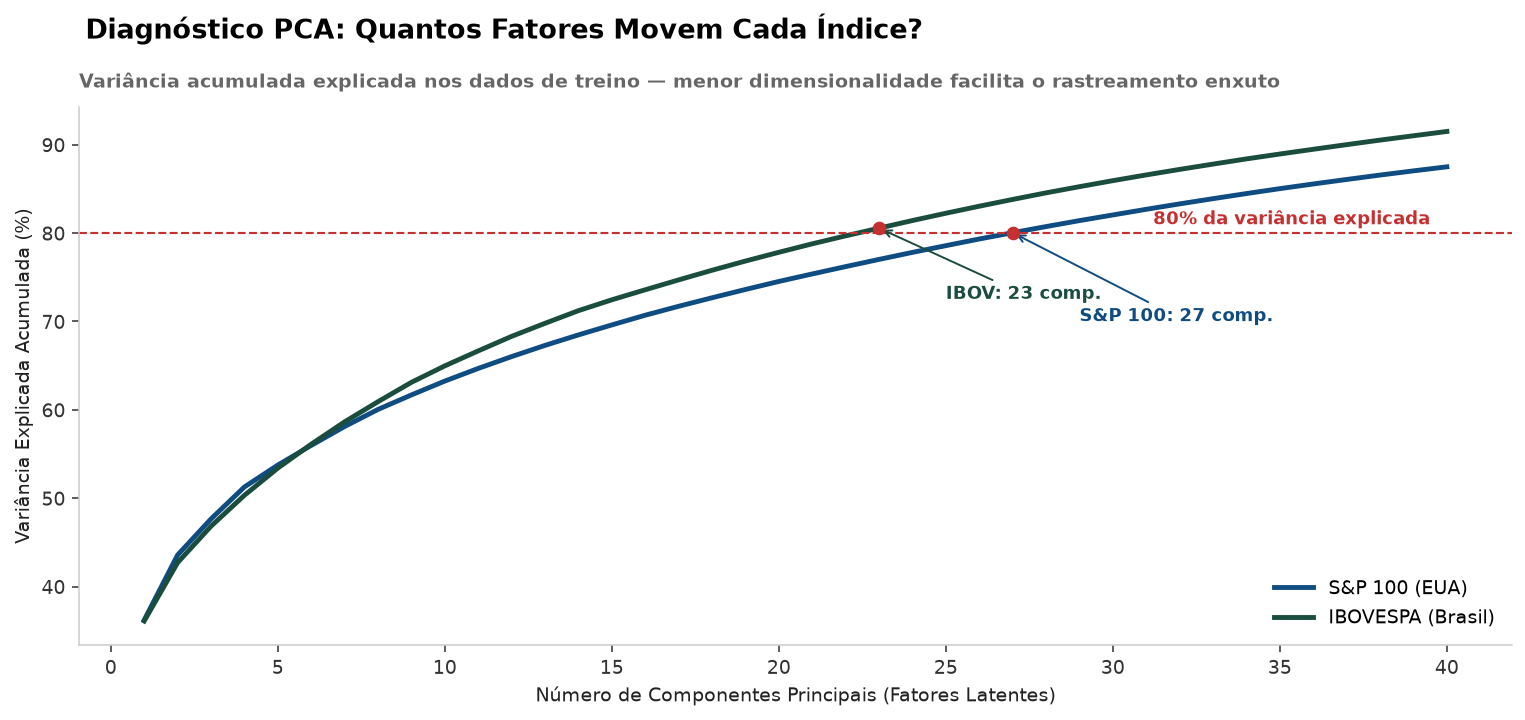

In [ ]:
def construir_features_treino(treino_X, treino_y, mapa_setores):
    """Calcula estatísticas descritivas e de risco por ativo exclusivamente no treino."""
    var_idx = treino_y.var()
    vol_idx = treino_y.std() * np.sqrt(252)
    corr_matrix = treino_X.corr()

    feats = pd.DataFrame(index=treino_X.columns)
    feats['corr_idx'] = treino_X.corrwith(treino_y)
    feats['beta'] = treino_X.apply(lambda s: s.cov(treino_y) / var_idx)
    feats['vol_anual'] = treino_X.std() * np.sqrt(252)
    feats['vol_ratio_idx'] = feats['vol_anual'] / vol_idx
    feats['te_individual'] = treino_X.sub(treino_y, axis=0).std() * np.sqrt(252)
    feats['corr_media_pares'] = (corr_matrix.sum() - 1.0) / (len(corr_matrix) - 1)

    # Drawdown máximo no treino (em base log-acumulada)
    acum = np.exp(treino_X.cumsum())
    pico = acum.cummax()
    feats['max_drawdown'] = ((acum - pico) / pico).min()
    feats['setor'] = feats.index.map(mapa_setores).fillna('Outros')
    return feats.sort_values('corr_idx', ascending=False)

feats_sp = construir_features_treino(dados_sp['treino_X'], dados_sp['treino_y'], dados_sp['setores'])
feats_ib = construir_features_treino(dados_ib['treino_X'], dados_ib['treino_y'], dados_ib['setores'])

# Diagnóstico de Dimensionalidade via PCA (Apenas no Treino)
pca_sp = PCA().fit(dados_sp['treino_X'])
pca_ib = PCA().fit(dados_ib['treino_X'])
var_sp = np.cumsum(pca_sp.explained_variance_ratio_) * 100
var_ib = np.cumsum(pca_ib.explained_variance_ratio_) * 100

fig, ax = plt.subplots(figsize=(11, 5.2), dpi=140)
ax.plot(range(1, 41), var_sp[:40], color=CORES['sp100'], lw=2.5, label='S&P 100 (EUA)')
ax.plot(range(1, 41), var_ib[:40], color=CORES['ibov'], lw=2.5, label='IBOVESPA (Brasil)')
ax.axhline(80, color=CORES['alerta'], ls='--', lw=1.1)
ax.text(39.5, 81, '80% da variância explicada', color=CORES['alerta'], fontweight='bold', fontsize=9, ha='right')

n80_sp = int(np.searchsorted(var_sp, 80.0) + 1)
n80_ib = int(np.searchsorted(var_ib, 80.0) + 1)
ax.scatter([n80_sp, n80_ib], [var_sp[n80_sp-1], var_ib[n80_ib-1]], color=CORES['alerta'], zorder=5)
ax.annotate(f'IBOV: {n80_ib} comp.', xy=(n80_ib, var_ib[n80_ib-1]), xytext=(n80_ib+2, var_ib[n80_ib-1]-8),
            arrowprops=dict(arrowstyle='->', color=CORES['ibov']), fontsize=9, fontweight='bold', color=CORES['ibov'])
ax.annotate(f'S&P 100: {n80_sp} comp.', xy=(n80_sp, var_sp[n80_sp-1]), xytext=(n80_sp+2, var_sp[n80_sp-1]-10),
            arrowprops=dict(arrowstyle='->', color=CORES['sp100']), fontsize=9, fontweight='bold', color=CORES['sp100'])

ax.set_xlabel('Número de Componentes Principais (Fatores Latentes)', fontsize=10)
ax.set_ylabel('Variância Explicada Acumulada (%)', fontsize=10)
ax.legend(frameon=False, loc='lower right', fontsize=10)
plt.suptitle('Diagnóstico PCA: Quantos Fatores Movem Cada Índice?', x=0.06, y=0.98, fontweight='bold', fontsize=14, ha='left')
ax.set_title('Variância acumulada explicada nos dados de treino — menor dimensionalidade facilita o rastreamento enxuto',
             fontsize=10, color='#666666', loc='left', pad=10)
plt.tight_layout()
plt.show()

In [ ]:
def checar_pesos(w, k_esperado=None, tol=1e-4):
    """Verificação formal das restrições matemáticas do problema MIQP/SLSQP."""
    assert abs(w.sum() - 1.0) <= tol, f"Erro: soma dos pesos = {w.sum():.6f} != 1"
    assert (w >= -tol).all(), "Erro: pesos negativos detectados (violação long-only)"
    if k_esperado is not None:
        n_ativos = int((w > 1e-5).sum())
        assert n_ativos <= k_esperado, f"Erro: {n_ativos} ativos > K={k_esperado}"
    return True

def filtrar_redundancia(treino_X, feats, top_n_candidatas=45, limite_par=0.90):
    """Remove ativos colineares mantendo o de maior correlação com o índice."""
    candidatas = feats.sort_values('corr_idx', ascending=False).head(top_n_candidatas).index.tolist()
    corr_c = treino_X[candidatas].corr()
    selecionadas = []
    for a in candidatas:
        if all(abs(corr_c.loc[a, s]) < limite_par for s in selecionadas):
            selecionadas.append(a)
    return selecionadas

# ------------------------------------------------------------------------------
# FAMÍLIA 1: Baseline 1 (Top K Correlação + Pesos Iguais 1/K)
# ------------------------------------------------------------------------------
def modelo_baseline_igual(treino_X, treino_y, feats, k):
    top_k = feats.sort_values('corr_idx', ascending=False).head(k).index
    w = pd.Series(1.0 / k, index=top_k)
    checar_pesos(w, k)
    return w

# ------------------------------------------------------------------------------
# FAMÍLIA 2: Baseline 2 (Top K Correlação + Pesos Inverso da Volatilidade 1/σ)
# ------------------------------------------------------------------------------
def modelo_baseline_inv_vol(treino_X, treino_y, feats, k):
    top_k = feats.sort_values('corr_idx', ascending=False).head(k).index
    inv_vol = 1.0 / feats.loc[top_k, 'vol_anual']
    w = inv_vol / inv_vol.sum()
    checar_pesos(w, k)
    return w

# ------------------------------------------------------------------------------
# OTIMIZADOR BASE SLSQP (Com ou Sem Penalização de Volatilidade da Finor)
# ------------------------------------------------------------------------------
def otimizar_slsqp(treino_X, treino_y, acoes, peso_max=1.0, lambda_vol=0.0):
    R = treino_X[acoes].values
    y = treino_y.values
    n = len(acoes)

    # Pré-cálculo da matriz de covariância anualizada e volatilidade do índice no treino
    cov_anual = np.cov(R, rowvar=False) * 252.0
    vol_idx_anual = np.std(y, ddof=1) * np.sqrt(252.0)

    def objetivo(w):
        mse_diario = np.mean((y - R @ w) ** 2)
        if lambda_vol > 0:
            vol_cart = np.sqrt(max(w.T @ cov_anual @ w, 1e-12))
            pen_vol = ((vol_cart - vol_idx_anual) ** 2) / 252.0
            return mse_diario + lambda_vol * pen_vol
        return mse_diario

    w0 = np.ones(n) / n
    lim_sup = max(peso_max, 1.0 / n + 1e-4)
    bounds = [(0.0, min(1.0, lim_sup))] * n
    restricoes = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]

    res = minimize(objetivo, x0=w0, method='SLSQP', bounds=bounds, constraints=restricoes,
                   options={'ftol': 1e-10, 'maxiter': 500})
    w_fin = pd.Series(np.maximum(res.x, 0.0), index=acoes)
    w_fin = w_fin[w_fin > 1e-5]
    w_fin = w_fin / w_fin.sum()
    checar_pesos(w_fin, len(acoes))
    return w_fin

# ------------------------------------------------------------------------------
# FAMÍLIA 3: Filtro de Redundância + Otimização SLSQP Pura (Foco Retorno)
# ------------------------------------------------------------------------------
def modelo_slsqp_puro(treino_X, treino_y, feats, k, peso_max=0.35):
    sem_red = filtrar_redundancia(treino_X, feats, top_n_candidatas=max(50, k*2), limite_par=0.90)
    escolhidas = sem_red[:k]
    return otimizar_slsqp(treino_X, treino_y, escolhidas, peso_max=peso_max, lambda_vol=0.0)

# ------------------------------------------------------------------------------
# FAMÍLIA 4: SLSQP + Ajuste de Volatilidade (Sugestão Finor: Retorno + Volatilidade)
# ------------------------------------------------------------------------------
def modelo_slsqp_vol_match(treino_X, treino_y, feats, k, peso_max=0.35, lambda_vol=0.25):
    sem_red = filtrar_redundancia(treino_X, feats, top_n_candidatas=max(50, k*2), limite_par=0.90)
    escolhidas = sem_red[:k]
    return otimizar_slsqp(treino_X, treino_y, escolhidas, peso_max=peso_max, lambda_vol=lambda_vol)

# ------------------------------------------------------------------------------
# FAMÍLIA 5: Lasso Positivo (Seleção L1 via Bisseção + Reotimização SLSQP)
# ------------------------------------------------------------------------------
def modelo_lasso_slsqp(treino_X, treino_y, feats, k, peso_max=0.35):
    X_val = treino_X.values
    y_val = treino_y.values
    low, high = 1e-7, 1e-2
    melhor_suporte = None

    for _ in range(30):
        mid = np.sqrt(low * high)
        m = Lasso(alpha=mid, positive=True, fit_intercept=False, max_iter=30000, random_state=42)
        m.fit(X_val, y_val)
        ativos_pos = treino_X.columns[m.coef_ > 1e-6].tolist()
        n_pos = len(ativos_pos)
        if 1 <= n_pos <= k:
            melhor_suporte = ativos_pos
            if n_pos == k:
                break
            high = mid  # reduz penalização para tentar chegar exatamente em K
        elif n_pos > k:
            low = mid   # aumenta penalização para zerar mais ativos
        else:
            high = mid

    if not melhor_suporte or len(melhor_suporte) < min(3, k):
        # Fallback seguro ordenando pelos maiores coeficientes de um alpha brando
        m = Lasso(alpha=2e-5, positive=True, fit_intercept=False, max_iter=30000, random_state=42)
        m.fit(X_val, y_val)
        coefs = pd.Series(m.coef_, index=treino_X.columns).sort_values(ascending=False)
        melhor_suporte = coefs.head(k).index.tolist()

    return otimizar_slsqp(treino_X, treino_y, melhor_suporte[:k], peso_max=peso_max, lambda_vol=0.05)

# ------------------------------------------------------------------------------
# FAMÍLIA 6: Clustering Hierárquico de Correlação + Otimização SLSQP (CORRIGIDO)
# ------------------------------------------------------------------------------
def modelo_clustering_slsqp(treino_X, treino_y, feats, k, peso_max=0.35):
    corr = treino_X.corr().clip(-1.0, 1.0)
    dist = np.sqrt(0.5 * (1.0 - corr))

    # Cria uma cópia explícita gravável (writeable) em NumPy para evitar erro read-only do Pandas 2.0+
    dist_matrix = dist.to_numpy(copy=True)
    np.fill_diagonal(dist_matrix, 0.0)

    try:
        cl = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    except TypeError:
        cl = AgglomerativeClustering(n_clusters=k, affinity='precomputed', linkage='average')

    rotulos = cl.fit_predict(dist_matrix)
    escolhidas = []
    for g in range(k):
        membros = treino_X.columns[rotulos == g]
        # Escolhe o representante do cluster com melhor razão (Correlação / Erro Individual)
        score = feats.loc[membros, 'corr_idx'] / feats.loc[membros, 'te_individual']
        escolhidas.append(score.idxmax())

    return otimizar_slsqp(treino_X, treino_y, escolhidas, peso_max=peso_max, lambda_vol=0.10)

In [9]:
def avaliar_modelo(pesos, ret_acoes, ret_indice, nome_modelo='Modelo'):
    """Calcula todas as métricas financeiras de aderência, risco e concentração."""
    r_cart = ret_acoes[pesos.index] @ pesos
    dif = r_cart - ret_indice

    te_anual = dif.std() * np.sqrt(252) * 100
    vol_cart = r_cart.std() * np.sqrt(252) * 100
    vol_idx = ret_indice.std() * np.sqrt(252) * 100
    gap_vol = abs(vol_cart - vol_idx)

    ret_acum_cart = (np.exp(r_cart.sum()) - 1.0) * 100
    ret_acum_idx = (np.exp(ret_indice.sum()) - 1.0) * 100
    td_acum = ret_acum_cart - ret_acum_idx

    corr = r_cart.corr(ret_indice)
    beta = r_cart.cov(ret_indice) / ret_indice.var()

    ss_res = ((ret_indice - r_cart) ** 2).sum()
    ss_tot = ((ret_indice - ret_indice.mean()) ** 2).sum()
    r2 = 1.0 - (ss_res / ss_tot)

    ir = (dif.mean() * 252 * 100) / te_anual if te_anual > 0 else np.nan
    hhi = (pesos ** 2).sum()

    return pd.Series({
        'Ativos (K)': int((pesos > 1e-5).sum()),
        'TE (% a.a.)': round(te_anual, 2),
        'Vol. Carteira (%)': round(vol_cart, 2),
        'Gap Vol. vs Índice (p.p.)': round(gap_vol, 2),
        'Track. Diff. Acum. (%)': round(td_acum, 2),
        'Correlação (r)': round(corr, 4),
        'R²': round(r2, 4),
        'Beta (β)': round(beta, 3),
        'Info. Ratio': round(ir, 3),
        'HHI (Concentração)': round(hhi, 3),
        'Peso Máx. (%)': round(pesos.max() * 100, 1)
    }, name=nome_modelo)

def rodar_spot_checking(dados_mercado, feats, k=15):
    tx, ty = dados_mercado['treino_X'], dados_mercado['treino_y']
    vx, vy = dados_mercado['val_X'], dados_mercado['val_y']
    test_x, test_y = dados_mercado['teste_X'], dados_mercado['teste_y']

    catalogo = {
        '1. Baseline: Top K Corr (1/K)': modelo_baseline_igual(tx, ty, feats, k),
        '2. Baseline: Top K Inv-Vol (1/σ)': modelo_baseline_inv_vol(tx, ty, feats, k),
        '3. SLSQP Puro (Sem Redundância)': modelo_slsqp_puro(tx, ty, feats, k),
        '4. SLSQP + Ajuste Vol. (Finor)': modelo_slsqp_vol_match(tx, ty, feats, k, lambda_vol=0.30),
        '5. Lasso Positivo (L1 + SLSQP)': modelo_lasso_slsqp(tx, ty, feats, k),
        '6. Clustering Hierárquico + SLSQP': modelo_clustering_slsqp(tx, ty, feats, k)
    }

    res_treino, res_val, res_teste = [], [], []
    for nome, w in catalogo.items():
        res_treino.append(avaliar_modelo(w, tx, ty, nome))
        res_val.append(avaliar_modelo(w, vx, vy, nome))
        res_teste.append(avaliar_modelo(w, test_x, test_y, nome))

    return catalogo, pd.DataFrame(res_treino), pd.DataFrame(res_val), pd.DataFrame(res_teste)

K_PADRAO = 15
pesos_sp, df_tr_sp, df_val_sp, df_te_sp = rodar_spot_checking(dados_sp, feats_sp, k=K_PADRAO)
pesos_ib, df_tr_ib, df_val_ib, df_te_ib = rodar_spot_checking(dados_ib, feats_ib, k=K_PADRAO)

print(f"================ SPOT-CHECKING NA VALIDAÇÃO (K={K_PADRAO}) — S&P 100 ================")
display(df_val_sp.sort_values('TE (% a.a.)'))

print(f"\n================ SPOT-CHECKING NA VALIDAÇÃO (K={K_PADRAO}) — IBOVESPA ================")
display(df_val_ib.sort_values('TE (% a.a.)'))

================ SPOT-CHECKING NA VALIDAÇÃO (K=15) — S&P 100 ================


,Ativos (K),TE (% a.a.),Vol. Carteira (%),Gap Vol. vs Índice (p.p.),Track. Diff. Acum. (%),Correlação (r),R²,Beta (β),Info. Ratio,HHI (Concentração),Peso Máx. (%)
3. SLSQP Puro (Sem Redundância),13.0,7.22,19.08,0.76,-7.69,0.9319,0.8672,0.896,-0.935,0.152,30.2
4. SLSQP + Ajuste Vol. (Finor),12.0,7.46,18.95,0.90,-7.76,0.9271,0.8582,0.885,-0.913,0.157,31.0
2. Baseline: Top K Inv-Vol (1/σ),15.0,8.08,24.25,4.41,2.76,0.9524,0.8343,1.164,0.287,0.071,9.7
1. Baseline: Top K Corr (1/K),15.0,9.61,26.13,6.29,8.11,0.9491,0.7651,1.250,0.693,0.067,6.7
5. Lasso Positivo (L1 + SLSQP),10.0,10.29,26.41,6.57,3.44,0.9401,0.7308,1.251,0.280,0.199,35.0
6. Clustering Hierárquico + SLSQP,11.0,11.13,15.35,4.49,-5.71,0.8297,0.6850,0.642,-0.446,0.197,35.0



================ SPOT-CHECKING NA VALIDAÇÃO (K=15) — IBOVESPA ================


,Ativos (K),TE (% a.a.),Vol. Carteira (%),Gap Vol. vs Índice (p.p.),Track. Diff. Acum. (%),Correlação (r),R²,Beta (β),Info. Ratio,HHI (Concentração),Peso Máx. (%)
6. Clustering Hierárquico + SLSQP,15.0,5.28,14.60,0.58,-6.62,0.9377,0.8783,0.902,-0.966,0.127,23.4
4. SLSQP + Ajuste Vol. (Finor),13.0,10.01,22.00,6.82,5.41,0.9196,0.5646,1.333,0.399,0.172,33.5
5. Lasso Positivo (L1 + SLSQP),13.0,10.14,22.77,7.59,-9.26,0.9348,0.5530,1.403,-0.712,0.134,22.2
2. Baseline: Top K Inv-Vol (1/σ),15.0,10.18,22.54,7.36,13.49,0.9278,0.5488,1.378,0.950,0.070,9.7
3. SLSQP Puro (Sem Redundância),13.0,10.20,22.23,7.05,4.65,0.9194,0.5482,1.346,0.337,0.164,32.4
1. Baseline: Top K Corr (1/K),15.0,10.98,23.31,8.14,12.34,0.9232,0.4754,1.418,0.809,0.067,6.7


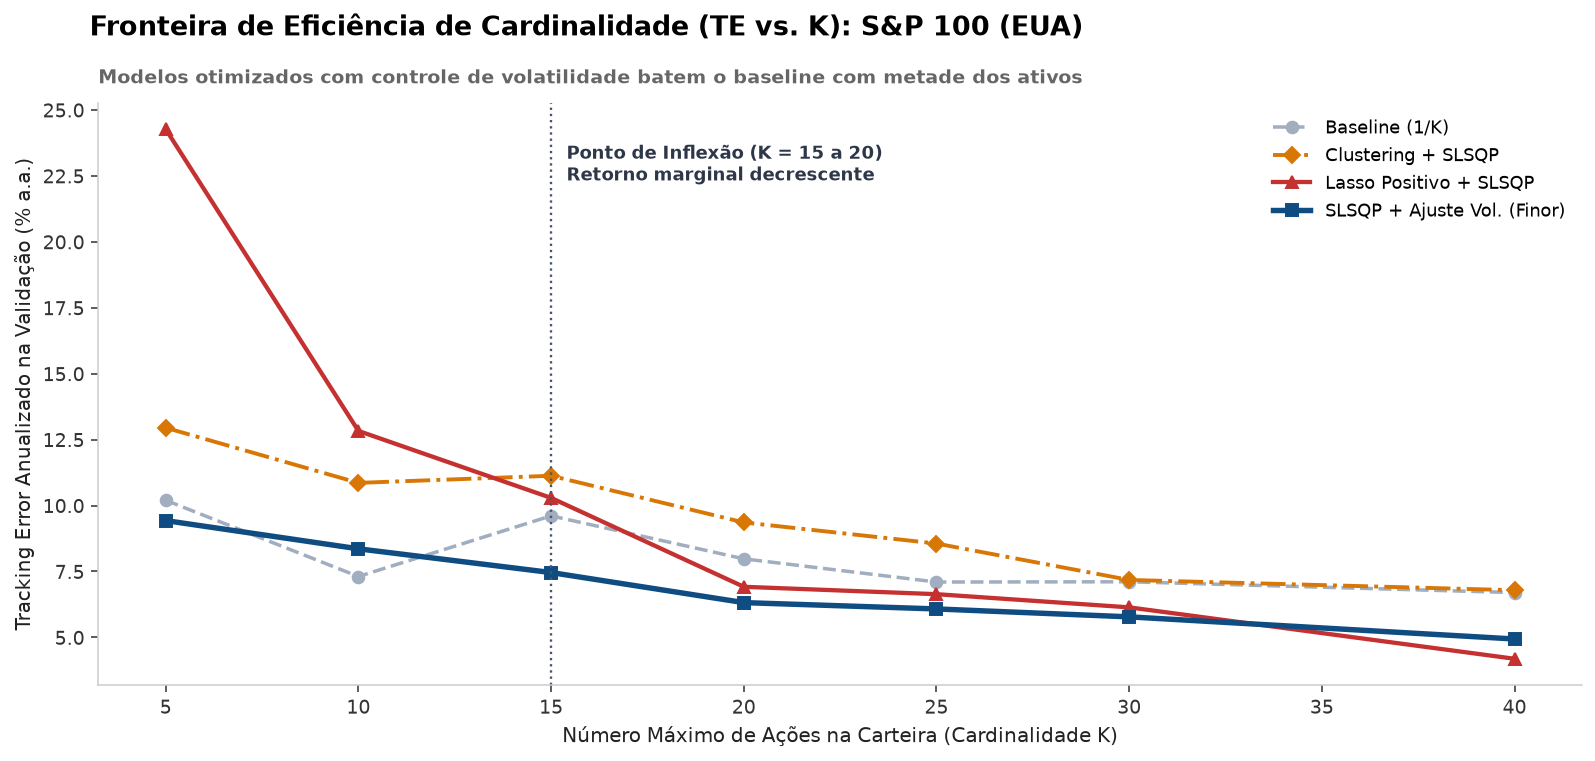

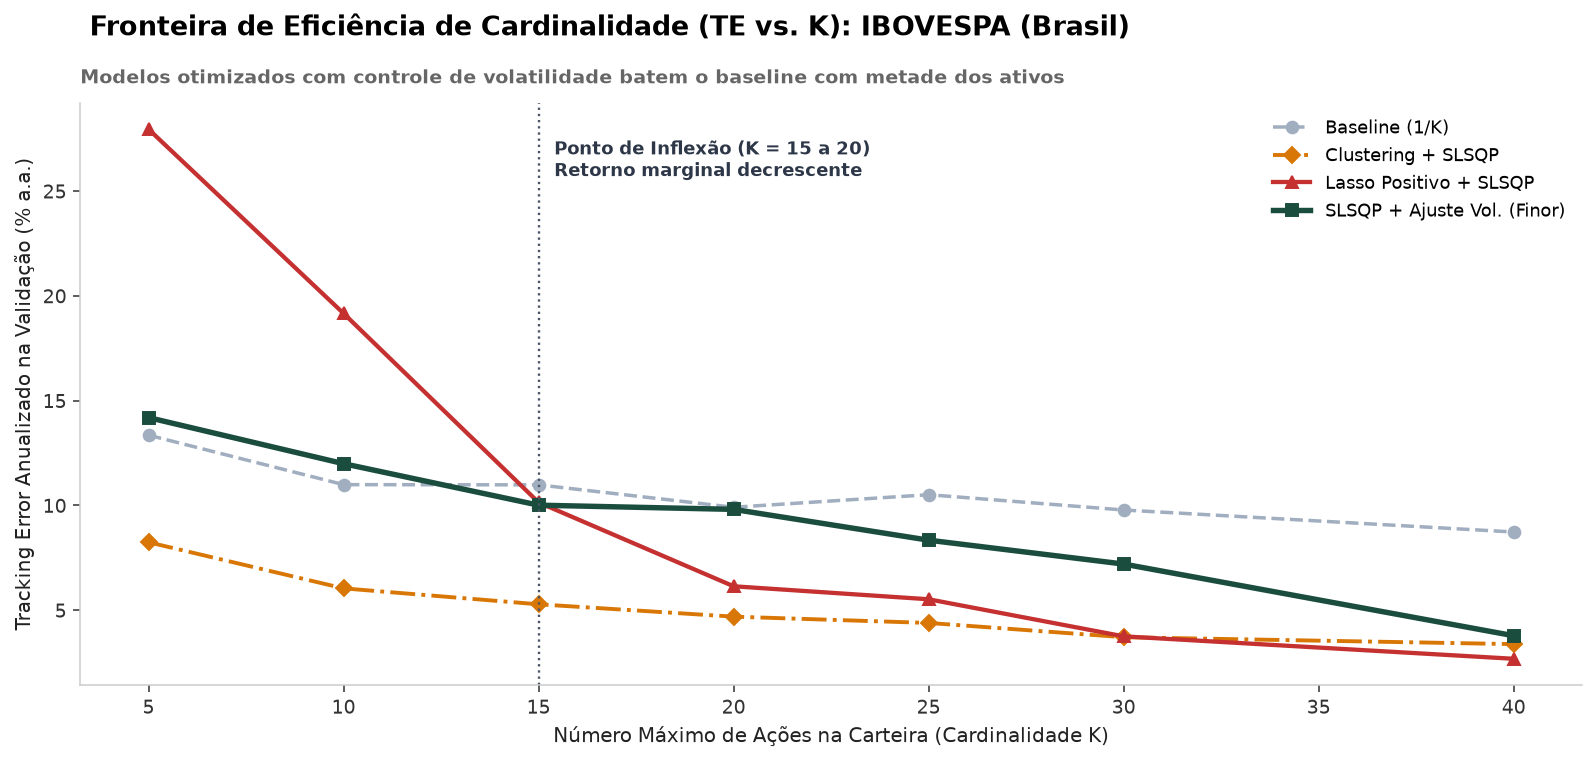

In [10]:
def plotar_curva_te_vs_k(dados_mercado, feats, nome_mercado, cor_principal):
    set_nyt_style()
    ks = [5, 10, 15, 20, 25, 30, 40]
    tx, ty = dados_mercado['treino_X'], dados_mercado['treino_y']
    vx, vy = dados_mercado['val_X'], dados_mercado['val_y']

    registros = []
    for k in ks:
        w_b1 = modelo_baseline_igual(tx, ty, feats, k)
        w_vol = modelo_slsqp_vol_match(tx, ty, feats, k, lambda_vol=0.30)
        w_las = modelo_lasso_slsqp(tx, ty, feats, k)
        w_clu = modelo_clustering_slsqp(tx, ty, feats, k)

        for nome_m, w in [
            ('Baseline (1/K)', w_b1),
            ('SLSQP + Ajuste Vol. (Finor)', w_vol),
            ('Lasso Positivo + SLSQP', w_las),
            ('Clustering + SLSQP', w_clu)
        ]:
            m = avaliar_modelo(w, vx, vy, nome_m)
            registros.append({'K': k, 'Modelo': nome_m, 'TE': m['TE (% a.a.)']})

    df_k = pd.DataFrame(registros)
    fig, ax = plt.subplots(figsize=(11.5, 5.5), dpi=140)

    estilos = {
        'Baseline (1/K)': (CORES['neutro'], '--', 'o', 1.8),
        'SLSQP + Ajuste Vol. (Finor)': (cor_principal, '-', 's', 2.8),
        'Lasso Positivo + SLSQP': (CORES['alerta'], '-', '^', 2.2),
        'Clustering + SLSQP': (CORES['laranja'], '-.', 'D', 2.0)
    }

    for mod, grp in df_k.groupby('Modelo'):
        c, ls, mk, lw = estilos[mod]
        ax.plot(grp['K'], grp['TE'], label=mod, color=c, linestyle=ls, marker=mk, linewidth=lw, markersize=6)

    # Anotação do "Joelho" da curva (K=15 a 20)
    ax.axvline(15, color='#4A5568', ls=':', lw=1.2)
    ax.text(15.4, df_k['TE'].max() * 0.92, 'Ponto de Inflexão (K = 15 a 20)\nRetorno marginal decrescente',
            fontsize=9, fontweight='bold', color='#2D3748')

    ax.set_xlabel('Número Máximo de Ações na Carteira (Cardinalidade K)', fontsize=10.5)
    ax.set_ylabel('Tracking Error Anualizado na Validação (% a.a.)', fontsize=10.5)
    ax.legend(frameon=False, fontsize=9.5, loc='upper right')
    plt.suptitle(f'Fronteira de Eficiência de Cardinalidade (TE vs. K): {nome_mercado}',
                 x=0.06, y=0.98, fontweight='bold', fontsize=14, ha='left')
    ax.set_title('Modelos otimizados com controle de volatilidade batem o baseline com metade dos ativos',
                 fontsize=10, color='#666666', loc='left', pad=10)
    plt.tight_layout()
    plt.show()
    return df_k

df_k_sp = plotar_curva_te_vs_k(dados_sp, feats_sp, 'S&P 100 (EUA)', CORES['sp100'])
df_k_ib = plotar_curva_te_vs_k(dados_ib, feats_ib, 'IBOVESPA (Brasil)', CORES['ibov'])

In [11]:
def validacao_walk_forward(dados_mercado, k=15, janela_meses=24, passo_meses=3, custo_bps=10):
    """
    Simula rebalanceamento trimestral deslizando janela de 24 meses.
    Calcula o Turnover médio e o impacto de custos de transação (ex: 10 bps = 0,10%).
    """
    ret_acoes = dados_mercado['ret_acoes']
    ret_idx = dados_mercado['ret_idx']
    setores = dados_mercado['setores']

    inicio = ret_acoes.index[0] + pd.DateOffset(months=janela_meses)
    pontos = pd.date_range(inicio, ret_acoes.index[-1], freq=f'{passo_meses}MS')
    if len(pontos) < 2 or pontos[-1] < ret_acoes.index[-1]:
        pontos = pontos.union([ret_acoes.index[-1]])

    ret_oos_bruto, ret_oos_liq, turnovers = [], [], []
    w_ant = pd.Series(dtype=float)

    for t0, t1 in zip(pontos[:-1], pontos[1:]):
        tr_x = ret_acoes.loc[t0 - pd.DateOffset(months=janela_meses): t0 - pd.Timedelta(days=1)]
        tr_y = ret_idx.loc[tr_x.index]
        feats_w = construir_features_treino(tr_x, tr_y, setores)

        w_novo = modelo_slsqp_vol_match(tr_x, tr_y, feats_w, k=k, lambda_vol=0.30)

        # Cálculo do Turnover na data de rebalanceamento t0
        uniao = w_novo.index.union(w_ant.index)
        turnover = 0.5 * (w_novo.reindex(uniao, fill_value=0.0) - w_ant.reindex(uniao, fill_value=0.0)).abs().sum()
        turnovers.append(turnover)
        w_ant = w_novo

        bloco_x = ret_acoes.loc[t0:t1, w_novo.index]
        if len(bloco_x) > 0:
            r_b = bloco_x @ w_novo
            r_l = r_b.copy()
            # Desconta custo de transação no 1º dia após o rebalanceamento
            r_l.iloc[0] -= turnover * (custo_bps / 10000.0)
            ret_oos_bruto.append(r_b)
            ret_oos_liq.append(r_l)

    s_bruto = pd.concat(ret_oos_bruto)
    s_bruto = s_bruto[~s_bruto.index.duplicated(keep='first')]
    s_liq = pd.concat(ret_oos_liq)
    s_liq = s_liq[~s_liq.index.duplicated(keep='first')]
    s_idx = ret_idx.loc[s_bruto.index]

    te_wf = (s_bruto - s_idx).std() * np.sqrt(252) * 100
    td_bruto = (np.exp(s_bruto.sum()) - np.exp(s_idx.sum())) * 100
    td_liq = (np.exp(s_liq.sum()) - np.exp(s_idx.sum())) * 100

    return {
        'TE Walk-Forward (% a.a.)': round(te_wf, 2),
        'Turnover Médio Trimestral (%)': round(np.mean(turnovers[1:]) * 100 if len(turnovers) > 1 else 0.0, 2),
        'Track. Diff. Bruta (%)': round(td_bruto, 2),
        'Track. Diff. Líquida (c/ 0,10% custo)': round(td_liq, 2),
        'N Janelas OOS': len(turnovers)
    }

wf_sp = validacao_walk_forward(dados_sp, k=15)
wf_ib = validacao_walk_forward(dados_ib, k=15)
print("=== RESULTADO WALK-FORWARD (REBALANCEAMENTO TRIMESTRAL, K=15) ===")
display(pd.DataFrame([wf_sp, wf_ib], index=['S&P 100', 'IBOVESPA']))

=== RESULTADO WALK-FORWARD (REBALANCEAMENTO TRIMESTRAL, K=15) ===


,TE Walk-Forward (% a.a.),Turnover Médio Trimestral (%),Track. Diff. Bruta (%),"Track. Diff. Líquida (c/ 0,10% custo)",N Janelas OOS
S&P 100,7.62,21.81,-17.53,-17.74,11
IBOVESPA,8.94,16.58,-9.53,-9.76,11
